# Activity7.02: Movie comparison revisited

LU MENGJIE — MC643920  
Suggested Exercise 07 · Practice 02

Data: `movie_scores.csv`. 

## Activity7.02 — 01. Read movie scores

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

DATA_DIR = Path('../../Datasets')
pd.set_option('display.max_columns', 8)
pd.set_option('display.width', 110)
print('LU MENGJIE | MC643920 | Python 3 / Seaborn', sns.__version__)
sns.set_theme()
movies = pd.read_csv(DATA_DIR / 'movie_scores.csv', index_col=0)
print('Movies:', len(movies))
display(movies)

LU MENGJIE | MC643920 | Python 3 / Seaborn 0.13.2
Movies: 5


,MovieTitle,Tomatometer,AudienceScore
0,The Shape of Water,91,73
1,Black Panther,97,79
2,Dunkirk,92,81
3,The Martian,91,91
4,The Hobbit: An Unexpected Journey,64,83


## Activity7.02 — 02. Reshape scores into long form

In [2]:
data = movies.melt(id_vars='MovieTitle',
                   value_vars=['AudienceScore', 'Tomatometer'],
                   var_name='Type', value_name='Scores')
data['Type'] = data['Type'].replace({'AudienceScore': 'Audience Score'})
print('Long-form records:', len(data))
display(data)

Long-form records: 10


,MovieTitle,Type,Scores
0,The Shape of Water,Audience Score,73
1,Black Panther,Audience Score,79
2,Dunkirk,Audience Score,81
3,The Martian,Audience Score,91
4,The Hobbit: An Unexpected Journey,Audience Score,83
5,The Shape of Water,Tomatometer,91
6,Black Panther,Tomatometer,97
7,Dunkirk,Tomatometer,92
8,The Martian,Tomatometer,91
9,The Hobbit: An Unexpected Journey,Tomatometer,64


## Activity7.02 — 03. Compare both scores with grouped bars

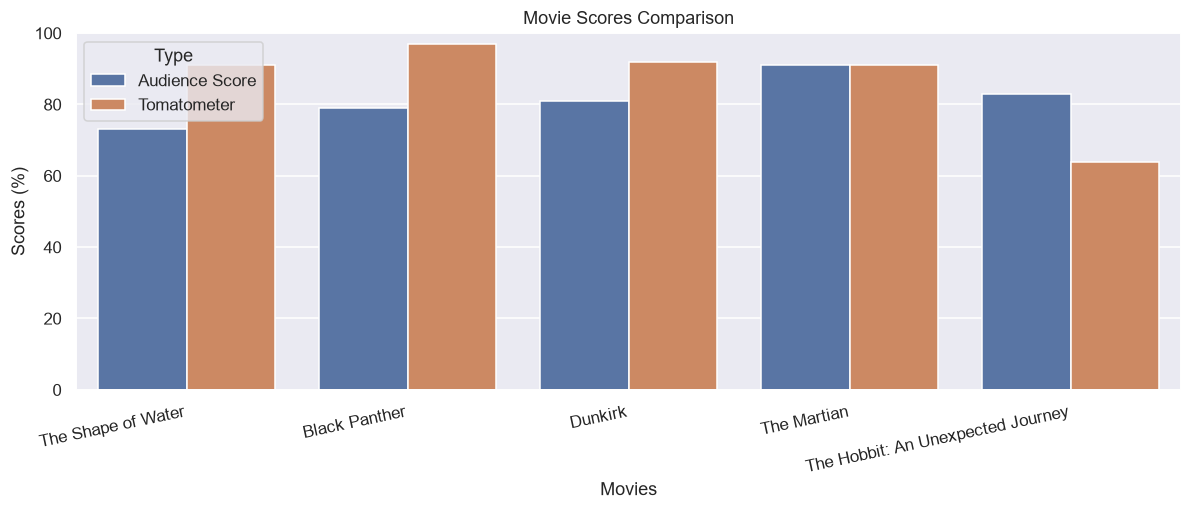

In [3]:
plt.figure(figsize=(11, 4.8), dpi=110)
sns.barplot(data=data, x='MovieTitle', y='Scores', hue='Type',
            hue_order=['Audience Score', 'Tomatometer'], errorbar=None)
plt.title('Movie Scores Comparison')
plt.xlabel('Movies')
plt.ylabel('Scores (%)')
plt.ylim(0, 100)
plt.xticks(rotation=12, ha='right')
plt.legend(title='Type', loc='upper left')
plt.tight_layout()
plt.show()

Critics score The Shape of Water, Black Panther, and Dunkirk higher than audiences do. Both scores are 91 for The Martian; audiences score The Hobbit: An Unexpected Journey higher than critics do. These are two different groups of reviewers.